# Ejercicio 2: aplicar dos convoluciones seguidas a una imagen

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT, clase de redes convolucionales

## Enunciado

Tomar una imagen y aplicarle dos convoluciones, es decir, filtrarla dos veces con kernels 3x3 distintos, y mostrar el resultado.

## Qué se hace

El segundo filtro no se aplica a la imagen original sino **a la salida del primero**:

$$I \;\xrightarrow{\;K_1\;}\; I_1 \;\xrightarrow{\;K_2\;}\; I_2$$

Se eligen dos kernels que se complementan:

- $K_1$: **desenfoque gaussiano**, que suaviza la imagen y atenúa el ruido.
- $K_2$: **relieve (emboss)**, que crea un efecto de iluminación en diagonal. Se eligió porque su efecto se nota mucho sobre la imagen ya suavizada, a diferencia de un detector de bordes, que da una imagen gris de poco contraste.

Primero se suaviza y después se realza el relieve. El kernel de relieve tiene pesos de hasta ±2 y amplifica el ruido, así que suavizar antes ayuda cuando la imagen tiene ruido, como se comprueba en la sección 4.

In [1]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import convolve2d


def cargar_imagen(ruta=None, modo="rgb"):
    """Foto de ejemplo incluida con matplotlib si no se da ruta. Valores en [0, 255]."""
    if ruta is None:
        ruta = os.path.join(matplotlib.get_data_path(), "sample_data", "grace_hopper.jpg")
    imagen = Image.open(ruta).convert("RGB" if modo == "rgb" else "L")
    return np.asarray(imagen, dtype=float)


def convolucion2d(img, kernel, padding="same"):
    """C(i,j) = suma_m suma_n I(i+m, j+n) K(m,n), sumando copias desplazadas de la imagen."""
    k = kernel.shape[0]
    if padding == "same":
        img = np.pad(img, k // 2, mode="constant")
    alto, ancho = img.shape[0] - k + 1, img.shape[1] - k + 1
    salida = np.zeros((alto, ancho))
    for m in range(k):
        for n in range(k):
            salida += kernel[m, n] * img[m:m + alto, n:n + ancho]
    return salida


def aplicar_filtro(img, kernel, padding="same"):
    """Filtra una imagen en gris (2D) o RGB (3D, canal por canal)."""
    if img.ndim == 2:
        return convolucion2d(img, kernel, padding)
    return np.stack([convolucion2d(img[..., c], kernel, padding) for c in range(3)], axis=-1)


def para_mostrar(resultado, kernel):
    """Lleva el resultado a [0, 255]: recorta si el kernel conserva brillo, normaliza si es de bordes."""
    if abs(kernel.sum()) > 0.5:
        return np.clip(resultado, 0, 255).astype(np.uint8)
    bajo, alto = np.percentile(resultado, [1, 99])
    return np.clip((resultado - bajo) / (alto - bajo) * 255, 0, 255).astype(np.uint8)

---

## 1. Los dos kernels

Sus sumas explican qué hacen: los dos suman 1, así que conservan el brillo general de la imagen. El gaussiano solo suaviza, porque todos sus pesos son positivos. El de relieve tiene pesos negativos y positivos: resta un lado de la vecindad y suma el opuesto, y de ahí sale el efecto de relieve.

In [2]:
K1 = np.array([[1, 2, 1],
               [2, 4, 2],
               [1, 2, 1]], dtype=float) / 16          # desenfoque gaussiano

K2 = np.array([[-2, -1, 0],
               [-1,  1, 1],
               [ 0,  1, 2]], dtype=float)             # relieve (emboss)

print("K1 (gaussiano):\n", K1, "\n   suma =", K1.sum())
print("\nK2 (relieve):\n", K2, "\n   suma =", K2.sum())

K1 (gaussiano):
 [[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]] 
   suma = 1.0

K2 (relieve):
 [[-2. -1.  0.]
 [-1.  1.  1.]
 [ 0.  1.  2.]] 
   suma = 1.0


---

## 2. Aplicar los dos filtros en cadena

Punto importante: el segundo filtro recibe la salida **numérica** del primero (sin recortar), no la versión ya convertida para dibujar.

In [3]:
imagen = cargar_imagen(modo="rgb")

imagen_1 = aplicar_filtro(imagen, K1)      # primera convolucion
imagen_2 = aplicar_filtro(imagen_1, K2)    # segunda convolucion, sobre la salida de la primera

print("original      :", imagen.shape,   "rango", (imagen.min(), imagen.max()))
print("despues de K1 :", imagen_1.shape, "rango", (round(imagen_1.min(), 1), round(imagen_1.max(), 1)))
print("despues de K2 :", imagen_2.shape, "rango", (round(imagen_2.min(), 1), round(imagen_2.max(), 1)))

original      : (600, 512, 3) rango (np.float64(0.0), np.float64(255.0))
despues de K1 : (600, 512, 3) rango (np.float64(0.0), np.float64(255.0))
despues de K2 : (600, 512, 3) rango (np.float64(-622.9), np.float64(955.2))


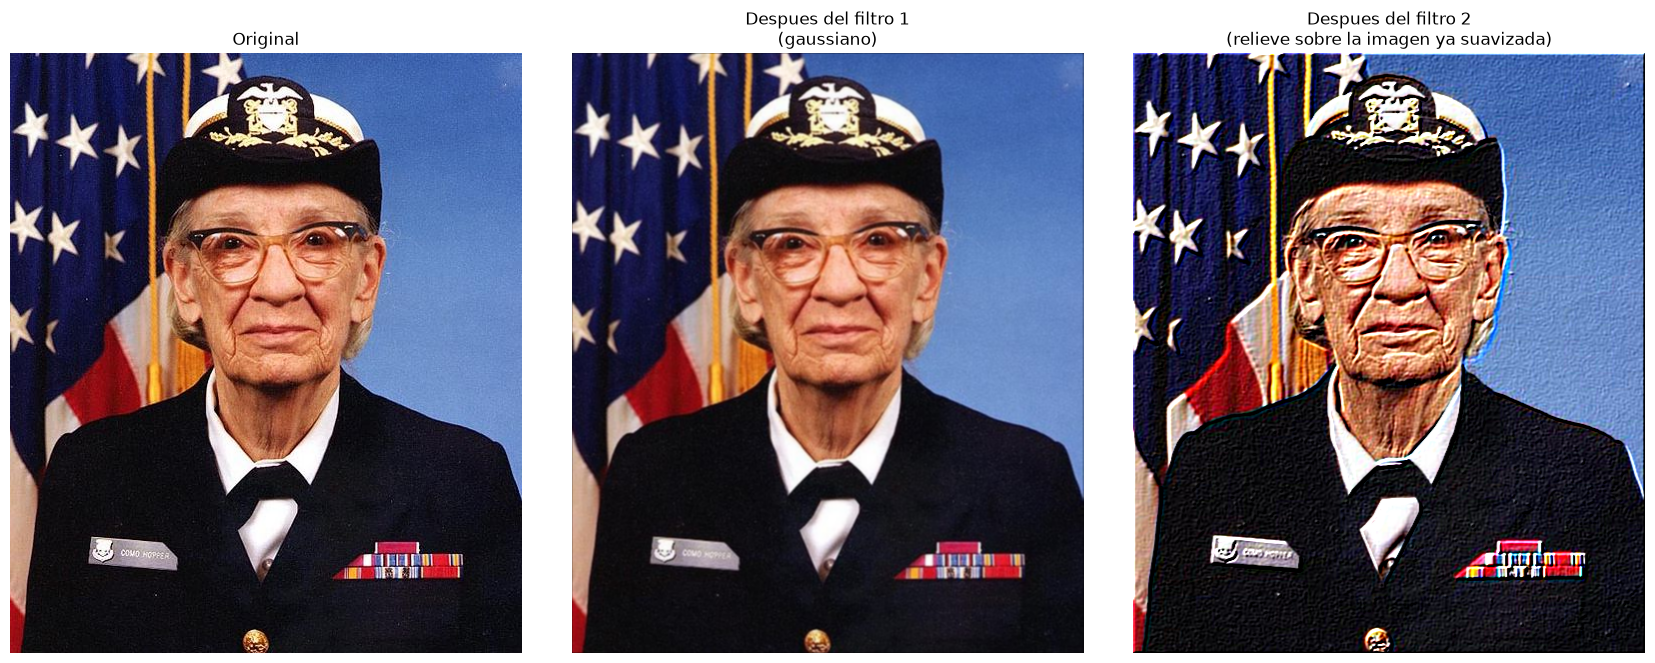

In [4]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 6.5))

ejes[0].imshow(imagen.astype(np.uint8))
ejes[0].set_title("Original")
ejes[1].imshow(para_mostrar(imagen_1, K1))
ejes[1].set_title("Despues del filtro 1\n(gaussiano)")
ejes[2].imshow(para_mostrar(imagen_2, K2))
ejes[2].set_title("Despues del filtro 2\n(relieve sobre la imagen ya suavizada)")

for eje in ejes:
    eje.axis("off")
plt.tight_layout()
plt.show()

El primer paso se nota poco, porque un desenfoque de 3x3 es suave, pero le quita el grano fino. El segundo paso se nota mucho: la imagen conserva sus colores y gana un relieve marcado, como si la luz llegara en diagonal, que resalta las arrugas, el contorno del sombrero, las estrellas y las cintas del uniforme.

---

## 3. Dos filtros seguidos equivalen a uno solo, más grande

Hay una propiedad que se puede comprobar. Aplicar $K_1$ y después $K_2$ da lo mismo que aplicar **un único kernel de 5x5**, que es la convolución completa de los dos kernels entre sí:

$$K_{eq} = K_1 * K_2 \qquad (3\times3)*(3\times3) \to (5\times5)$$

Esto es exactamente lo que pasa en una CNN cuando se apilan capas: cada capa de 3x3 extiende el campo que "ve" cada píxel de salida, y dos capas ven una ventana de 5x5.

In [5]:
gris = cargar_imagen(modo="gris")

en_cadena = aplicar_filtro(aplicar_filtro(gris, K1), K2)

K_equivalente = convolve2d(K1, K2, mode="full")
un_solo_paso = aplicar_filtro(gris, K_equivalente)

print("Kernel equivalente", K_equivalente.shape, ":")
print(np.round(K_equivalente, 4))

# Se compara en el interior: el relleno de ceros del borde no es el mismo
# en los dos casos (se rellena dos veces contra una vez).
interior = (slice(2, -2), slice(2, -2))
print("\nEn el interior, K1 luego K2 == un solo kernel de 5x5:",
      np.allclose(en_cadena[interior], un_solo_paso[interior]))
print("Diferencia maxima en el interior:", np.abs(en_cadena[interior] - un_solo_paso[interior]).max())
print("Diferencia maxima en el borde   :", round(np.abs(en_cadena - un_solo_paso).max(), 1),
      "(por el relleno de ceros)")

Kernel equivalente (5, 5) :
[[-0.125  -0.3125 -0.25   -0.0625  0.    ]
 [-0.3125 -0.6875 -0.375   0.0625  0.0625]
 [-0.25   -0.375   0.25    0.625   0.25  ]
 [-0.0625  0.0625  0.625   0.8125  0.3125]
 [ 0.      0.0625  0.25    0.3125  0.125 ]]

En el interior, K1 luego K2 == un solo kernel de 5x5: True
Diferencia maxima en el interior: 0.0
Diferencia maxima en el borde   : 176.4 (por el relleno de ceros)


### 3.1 El orden no importa (si no hay nada entre los filtros)

La convolución es conmutativa: $K_1$ luego $K_2$ da lo mismo que $K_2$ luego $K_1$.

In [6]:
al_reves = aplicar_filtro(aplicar_filtro(gris, K2), K1)
print("K1 luego K2 == K2 luego K1 (interior):", np.allclose(en_cadena[interior], al_reves[interior]))

K1 luego K2 == K2 luego K1 (interior): True


### 3.2 Pero una no linealidad entre los filtros lo rompe

En una CNN entre capa y capa hay una activación, normalmente ReLU. Ahí ya **no** se puede reducir todo a un solo kernel. Ojo con un detalle que conviene comprobar en vez de suponer: con el gaussiano primero, el ReLU no cambia nada, porque desenfocar una imagen de valores positivos no produce valores negativos y no hay nada que recortar. Para que importe, el primer filtro tiene que producir negativos, como el de relieve.

In [7]:
relu = lambda x: np.maximum(x, 0)

# Caso A: gaussiano -> ReLU -> relieve.  El gaussiano no produce negativos.
inter_a = aplicar_filtro(gris, K1)
sale_a = aplicar_filtro(relu(inter_a), K2)
print(f"Caso A (gaussiano primero): valores negativos tras K1 = {100*np.mean(inter_a < 0):.0f}%")
print("   con ReLU en medio, igual al kernel 5x5:", np.allclose(sale_a[interior], un_solo_paso[interior]))

# Caso B: relieve -> ReLU -> gaussiano.  El relieve si produce negativos.
inter_b = aplicar_filtro(gris, K2)
sale_b = aplicar_filtro(relu(inter_b), K1)
print(f"\nCaso B (relieve primero): valores negativos tras K2 = {100*np.mean(inter_b < 0):.0f}%")
print("   con ReLU en medio, igual al kernel 5x5:", np.allclose(sale_b[interior], un_solo_paso[interior]))
print("   diferencia maxima:", round(np.abs(sale_b[interior] - un_solo_paso[interior]).max(), 1))

Caso A (gaussiano primero): valores negativos tras K1 = 0%
   con ReLU en medio, igual al kernel 5x5: True

Caso B (relieve primero): valores negativos tras K2 = 14%
   con ReLU en medio, igual al kernel 5x5: False
   diferencia maxima: 621.8


En el caso B la equivalencia se rompe: el ReLU descartó los valores negativos que había calculado el relieve (alrededor del 14% de los píxeles), y esa información ya no se puede recuperar con un kernel único. **Esa es la razón de ser de la no linealidad en una red**: sin ella, apilar 100 capas convolucionales sería lo mismo que tener una sola.

---

## 4. ¿Para qué sirve filtrar primero con el gaussiano?

Para comprobarlo se le agrega ruido a la imagen y se compara la salida con la que se obtendría de la imagen limpia. La comparación usa el coeficiente de correlación: 1 significa que la salida es idéntica a la ideal.

In [8]:
relieve_ideal = aplicar_filtro(gris, K2)        # relieve sobre la imagen sin ruido
rng = np.random.RandomState(0)

print(f"{'ruido (sigma)':>14} | {'solo relieve':>13} | {'gaussiano + relieve':>20}")
print("-" * 54)
for sigma in [10, 25, 40]:
    ruidosa = gris + rng.normal(0, sigma, gris.shape)
    solo = aplicar_filtro(ruidosa, K2)
    ambos = aplicar_filtro(aplicar_filtro(ruidosa, K1), K2)
    corr = lambda a: np.corrcoef(a.ravel(), relieve_ideal.ravel())[0, 1]
    print(f"{sigma:>14} | {corr(solo):>13.3f} | {corr(ambos):>20.3f}")

 ruido (sigma) |  solo relieve |  gaussiano + relieve
------------------------------------------------------
            10 |         0.959 |                0.957
            25 |         0.803 |                0.898
            40 |         0.643 |                0.814


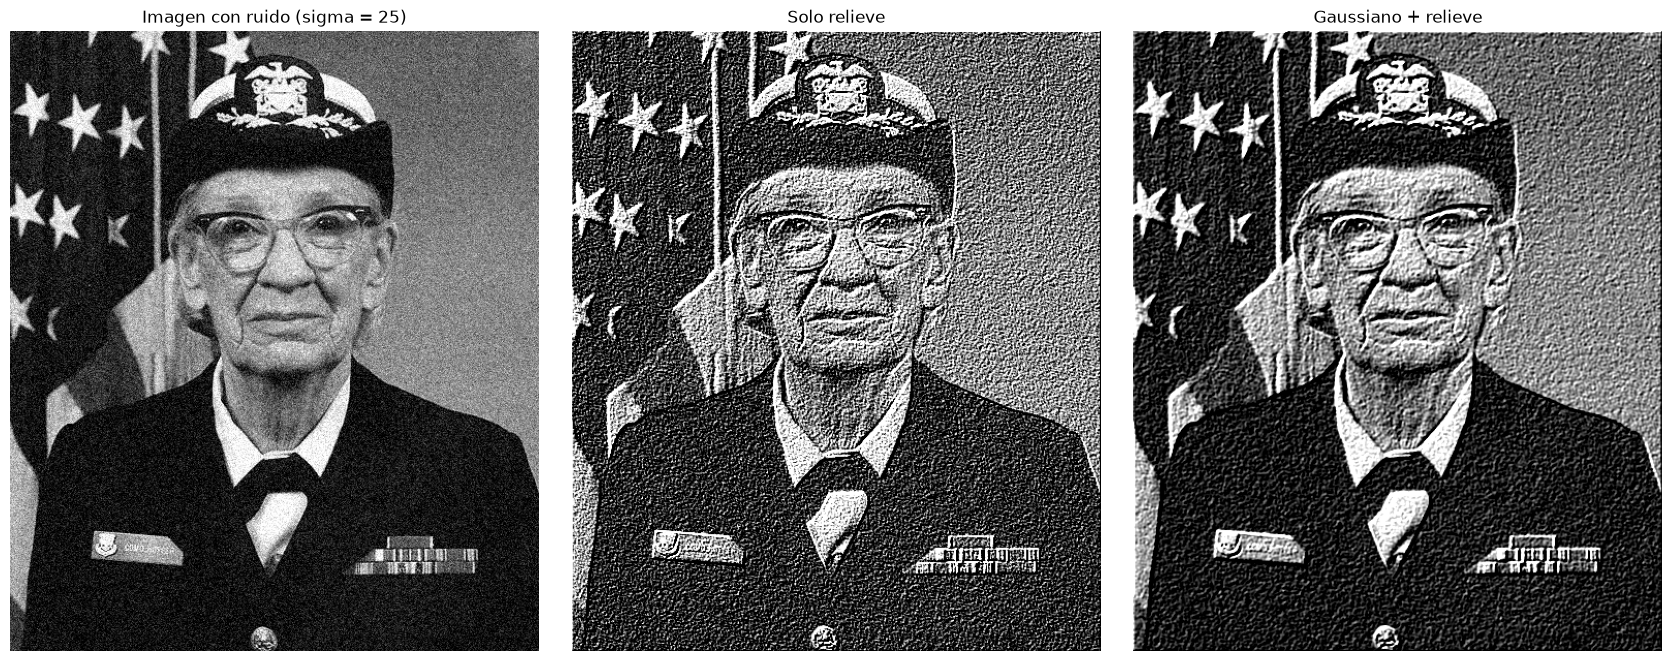

In [9]:
ruidosa = gris + np.random.RandomState(1).normal(0, 25, gris.shape)
solo = aplicar_filtro(ruidosa, K2)
ambos = aplicar_filtro(aplicar_filtro(ruidosa, K1), K2)

fig, ejes = plt.subplots(1, 3, figsize=(17, 6.5))
for eje, im, titulo in [(ejes[0], np.clip(ruidosa, 0, 255).astype(np.uint8), "Imagen con ruido (sigma = 25)"),
                        (ejes[1], para_mostrar(solo, K2), "Solo relieve"),
                        (ejes[2], para_mostrar(ambos, K2), "Gaussiano + relieve")]:
    eje.imshow(im, cmap="gray", vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()

Con ruido leve el gaussiano **no ayuda** (la correlación incluso baja un poco): también suaviza bordes que sí eran reales. Con ruido moderado o fuerte la mejora es clara, porque el desenfoque promedia el ruido antes de que el kernel de relieve, que resta vecinos con pesos grandes, lo amplifique. En la imagen de arriba se nota como menos grano en "gaussiano + relieve", pero el respaldo firme de la comparación son los números de la tabla, no el ojo.

---

## 5. Conclusiones

**Filtrar dos veces es componer.** El segundo kernel actúa sobre lo que dejó el primero. Con dos filtros distintos se obtiene algo que ninguno hace solo: aquí, un relieve limpio a partir de una imagen ruidosa.

**Dos filtros lineales seguidos son un filtro más grande.** Un kernel de 3x3 seguido de otro de 3x3 equivale exactamente a uno de 5x5, y el orden no importa. Es la base de por qué una CNN apila capas pequeñas: cada una amplía la zona de la imagen que influye en cada salida.

**Lo que evita que todo se reduzca a un solo filtro es la no linealidad.** Con un ReLU entre los dos filtros, la equivalencia se rompe, y solo si el filtro anterior produce valores negativos: con el gaussiano primero el ReLU no hace nada, porque no hay negativos que descartar.

**Encadenar no siempre gana.** Con ruido leve, el desenfoque previo empeora un poco el resultado. Es un compromiso entre quitar ruido y conservar detalle, y en una CNN esa decisión no se toma a mano: la red aprende los kernels.